"C:\Users\Dell\Documents\Downloads\stores_sales_forecasting.csv"

**Step 1: import libraries**

In [2]:
# data handling
import joblib 
import pandas as pd
import numpy as np

# data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, RandomizedSearchCV
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import VarianceThreshold

# regression models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from xgboost import XGBRegressor

# metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score

**Step 2: load dataset**

In [26]:
df = pd.read_csv(r"C:\Users\Dell\Documents\Downloads\stores_sales_forecasting.csv", encoding="utf-8", encoding_errors="ignore")

**Step 3: understand your data**

In [10]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
3,6,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,FUR-FU-10001487,Furniture,Furnishings,Eldon Expressions Wood and Plastic Desk Access...,48.8600,7,0.00,14.1694
4,11,CA-2014-115812,6/9/2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,FUR-TA-10001539,Furniture,Tables,Chromcraft Rectangular Conference Tables,1706.1840,9,0.20,85.3092


In [11]:
df.sample(5)

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
1610,7605,CA-2016-101791,5/27/2016,5/31/2016,Standard Class,BS-11665,Brian Stugart,Consumer,United States,Chicago,Illinois,60623,Central,FUR-FU-10003247,Furniture,Furnishings,36X48 HARDFLOOR CHAIRMAT,25.176,3,0.6,-33.3582
389,1872,CA-2014-116932,7/21/2014,7/25/2014,Standard Class,ME-18010,Michelle Ellison,Corporate,United States,San Francisco,California,94122,West,FUR-CH-10001215,Furniture,Chairs,Global Troy Executive Leather Low-Back Tilter,801.568,2,0.2,50.0980
1639,7724,CA-2015-139374,9/10/2015,9/14/2015,Standard Class,AR-10345,Alex Russell,Corporate,United States,Austin,Texas,78745,Central,FUR-CH-10003981,Furniture,Chairs,Global Commerce Series Low-Back Swivel/Tilt Ch...,179.886,1,0.3,-2.5698
580,2803,CA-2017-143329,11/3/2017,11/8/2017,Standard Class,DL-13330,Denise Leinenbach,Consumer,United States,Las Cruces,New Mexico,88001,West,FUR-FU-10000629,Furniture,Furnishings,9-3/4 Diameter Round Wall Clock,41.370,3,0.0,17.3754
1114,5361,US-2017-126060,4/14/2017,4/18/2017,Standard Class,DW-13585,Dorothy Wardle,Corporate,United States,Fayetteville,North Carolina,28314,South,FUR-BO-10003433,Furniture,Bookcases,Sauder Cornerstone Collection Library,198.272,8,0.2,-32.2192


In [12]:
df.dtypes

Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [13]:
df.nunique()

Row ID           2121
Order ID         1764
Order Date        889
Ship Date         960
Ship Mode           4
Customer ID       707
Customer Name     707
Segment             3
Country             1
City              371
State              48
Postal Code       454
Region              4
Product ID        375
Category            1
Sub-Category        4
Product Name      380
Sales            1636
Quantity           14
Discount           11
Profit           1777
dtype: int64

In [15]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State',
       'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category',
       'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit'],
      dtype='str')

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2121 entries, 0 to 2120
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         2121 non-null   int64  
 1   Order ID       2121 non-null   str    
 2   Order Date     2121 non-null   str    
 3   Ship Date      2121 non-null   str    
 4   Ship Mode      2121 non-null   str    
 5   Customer ID    2121 non-null   str    
 6   Customer Name  2121 non-null   str    
 7   Segment        2121 non-null   str    
 8   Country        2121 non-null   str    
 9   City           2121 non-null   str    
 10  State          2121 non-null   str    
 11  Postal Code    2121 non-null   int64  
 12  Region         2121 non-null   str    
 13  Product ID     2121 non-null   str    
 14  Category       2121 non-null   str    
 15  Sub-Category   2121 non-null   str    
 16  Product Name   2121 non-null   str    
 17  Sales          2121 non-null   float64
 18  Quantity       2121

In [16]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,2121.000000,2121.000000,2121.000000,2121.000000,2121.000000,2121.000000
mean,5041.643564,55726.556341,349.834887,3.785007,0.173923,8.699327
std,2885.740258,32261.888225,503.179145,2.251620,0.181547,136.049246
min,1.000000,1040.000000,1.892000,1.000000,0.000000,-1862.312400
25%,2568.000000,22801.000000,47.040000,2.000000,0.000000,-12.849000
50%,5145.000000,60505.000000,182.220000,3.000000,0.200000,7.774800
75%,7534.000000,90032.000000,435.168000,5.000000,0.300000,33.726600
max,9991.000000,99301.000000,4416.174000,14.000000,0.700000,1013.127000


In [17]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [18]:
df.duplicated().sum()

np.int64(0)

**Step 4: Data cleaning**

In [ ]:
# 1. remove null values
# df.dropna(inplace=True)

In [ ]:
# 2. remove duplicates
# df.drop_duplicates(inplace=True)

In [27]:
# 3. fix data types
df['Order Date'] = pd.to_datetime(df['Order Date'], format='%Y-%m-%d', errors='coerce')
df['Ship Date'] = pd.to_datetime(df['Ship Date'], format='%Y-%m-%d', errors='coerce')

In [28]:
# 4. fix column names
rename_dict = {
    'Order Date': 'order_date',
    'Ship Date': 'ship_date',
    'Ship Mode': 'ship_mode',
    'Customer Name': 'customer_name',
    'Product Name': 'product_name',
    'Segment': 'segment',
    'Country': 'country',
    'City': 'city',
    'State': 'state',
    'Region': 'region',
    'Category': 'category',
    'Sub-Category': 'sub_category',
    'Sales': 'sales',
    'Quantity': 'quantity',
    'Discount': 'discount',
    'Profit': 'profit'
}
df.rename(columns=rename_dict, inplace=True)

In [33]:
# remove unwanted cols
df.drop(columns=['Row ID', 'Order ID','Customer ID','Product ID','Postal Code'], inplace=True)

In [35]:
df.drop(columns=['order_date', 'ship_date'], inplace=True)

In [44]:
df.drop(columns=['country'], inplace=True)

In [29]:
# 5. remove outliers
numeric_cols = ['sales', 'quantity', 'discount', 'profit']
for i,col in enumerate(numeric_cols):
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    print(f"\n{i}: {col}")
    before_outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"before outliers: {len(before_outliers)}")
    df = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)]
    after_outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"after outliers: {len(after_outliers)}")



0: sales
before outliers: 164
after outliers: 0

1: quantity
before outliers: 24
after outliers: 0

2: discount
before outliers: 0
after outliers: 0

3: profit
before outliers: 336
after outliers: 0


**Step 5: Feature engineering**

In [38]:
df['profit_margin'] = df['profit'] / df['sales']
df['sales_per_quantity'] = df['sales'] / df['quantity']
df['discount_amount'] = df['sales'] * df['discount']
df['profit_per_quantity'] = df['profit'] / df['quantity']
df['quantity_discount'] = df['quantity'] * df['discount']

**Step 6: Data visualization**

Univariate:

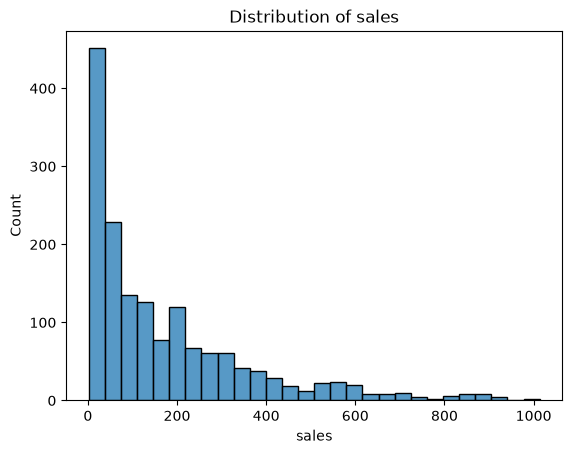

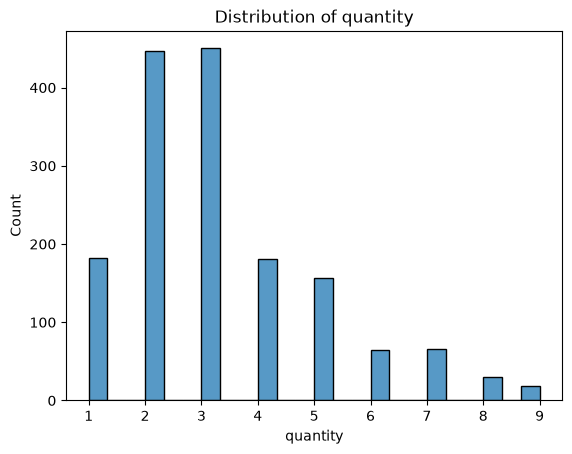

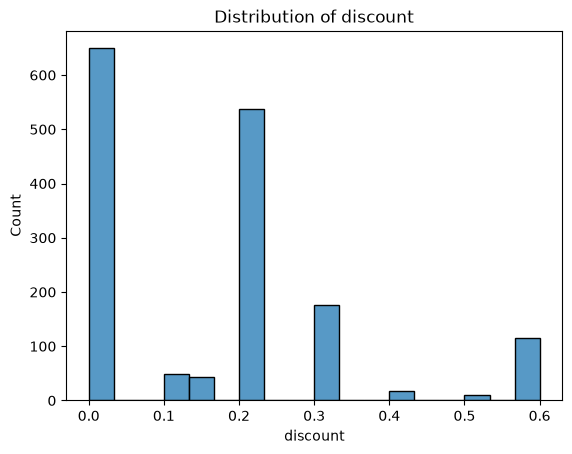

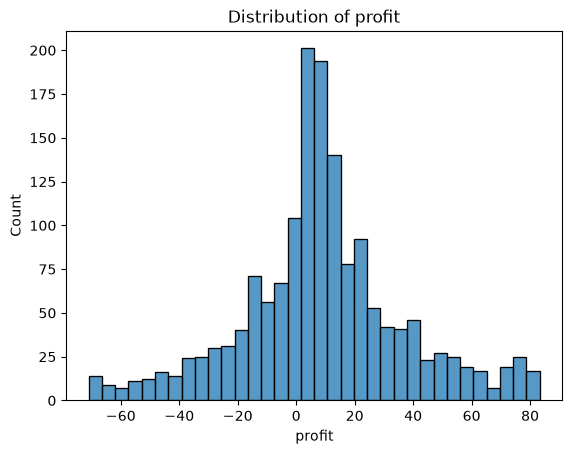

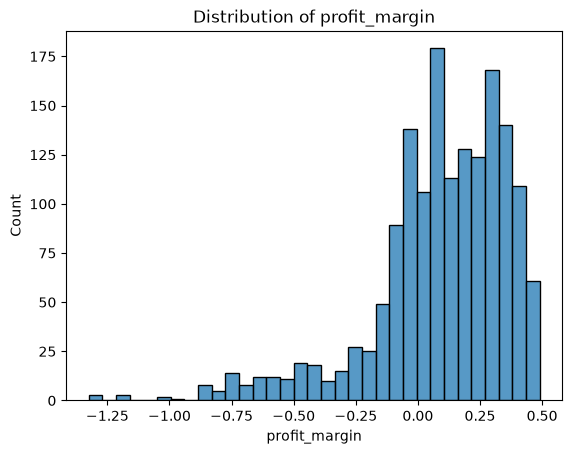

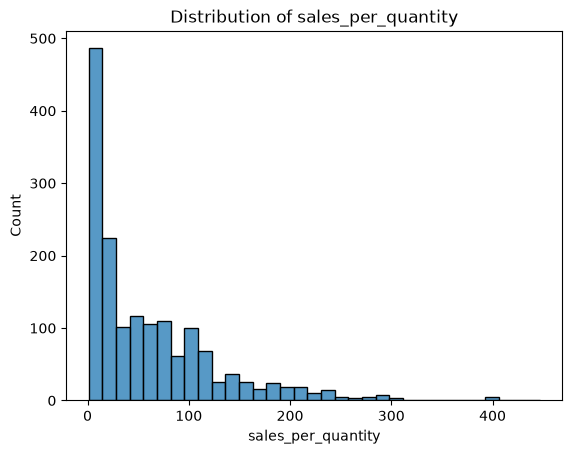

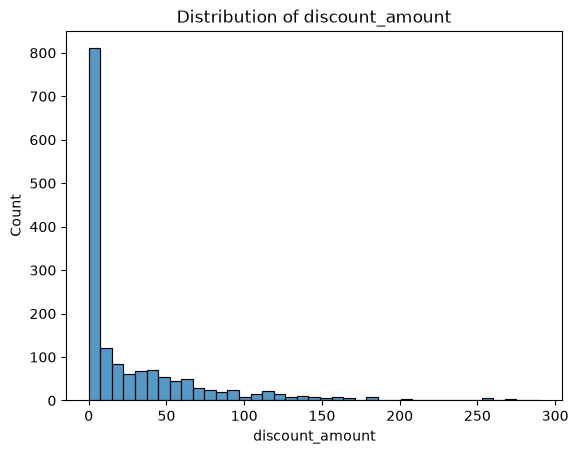

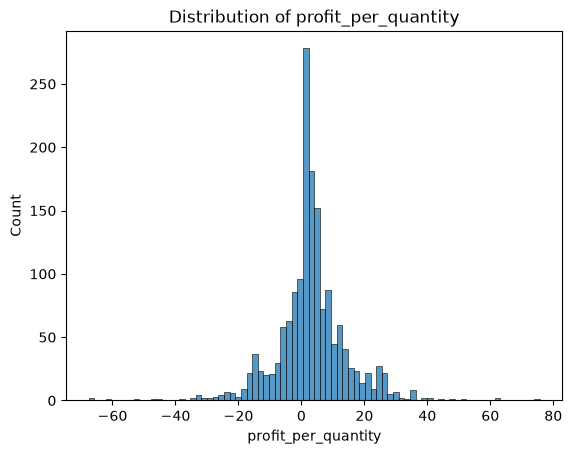

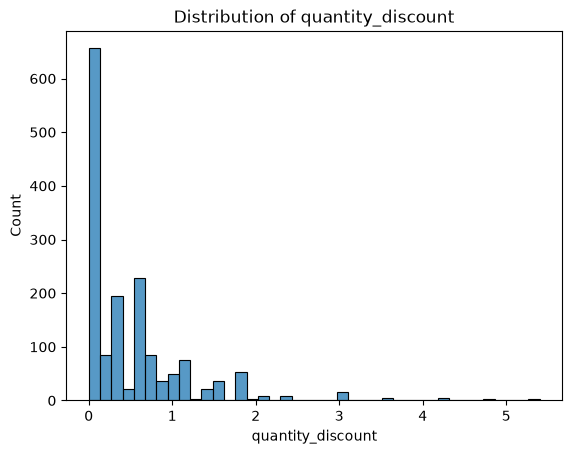

In [41]:
nums = df.select_dtypes(include=['int64', 'float64']).columns.tolist()
for n in nums:
    sns.histplot(data=df, x=n)
    plt.title(f'Distribution of {n}')
    plt.show()

In [47]:
df['category'].value_counts()

category
Furniture    1597
Name: count, dtype: int64

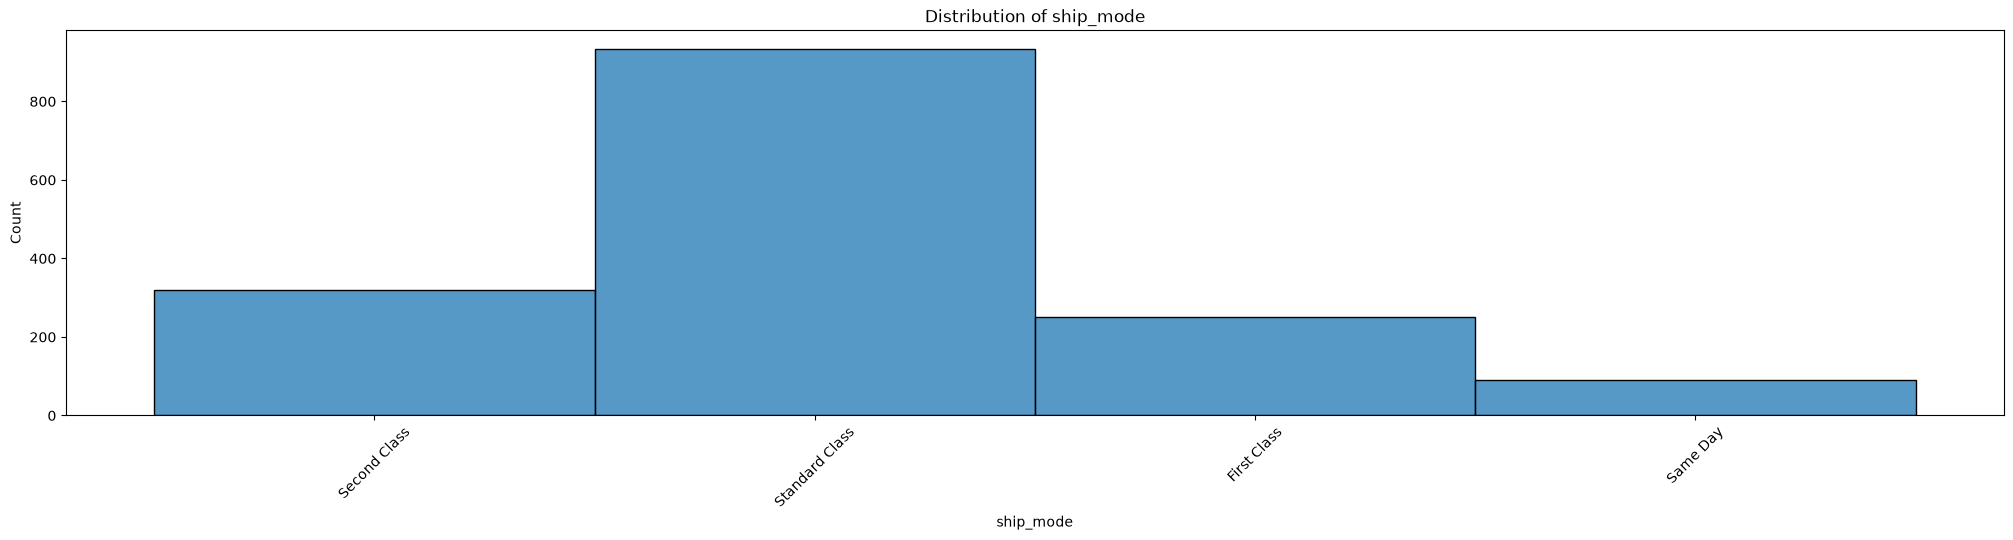

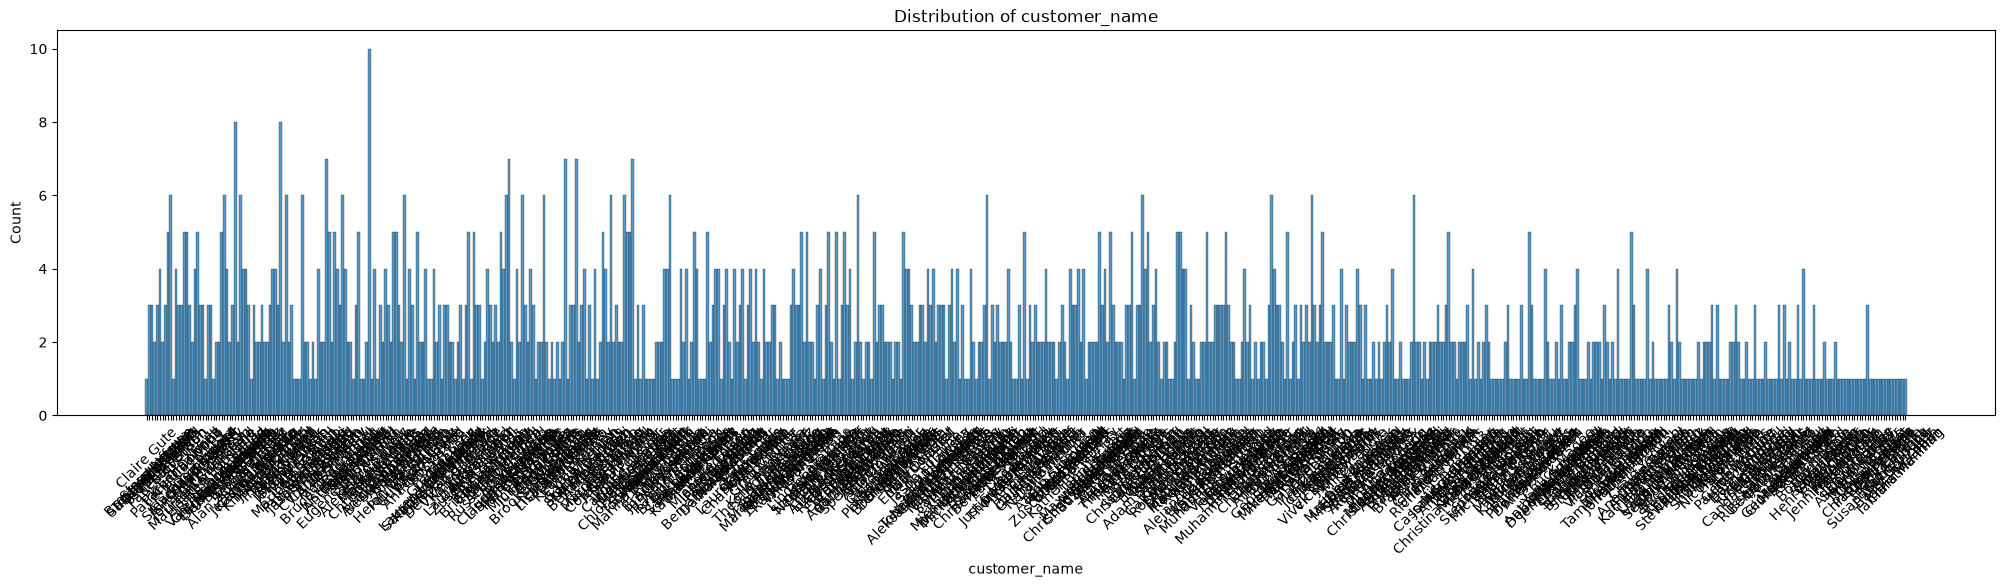

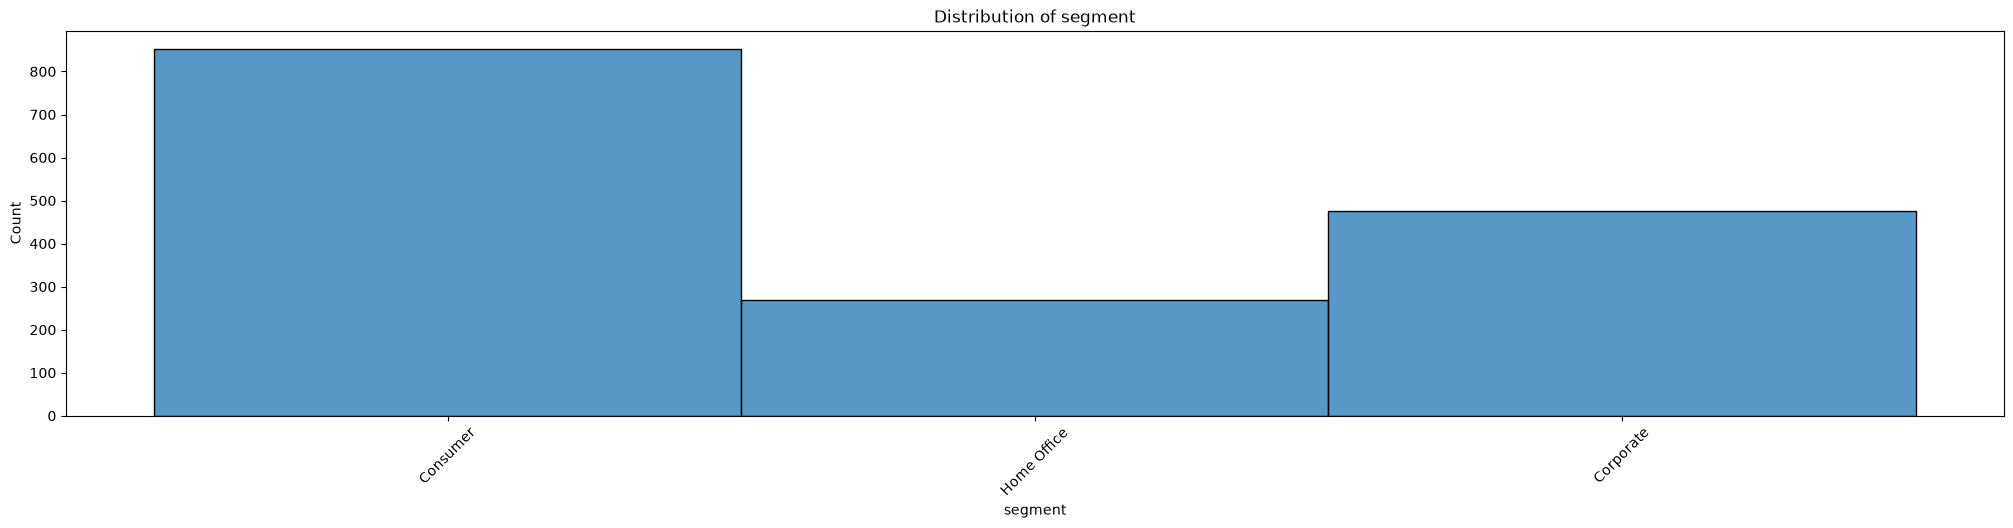

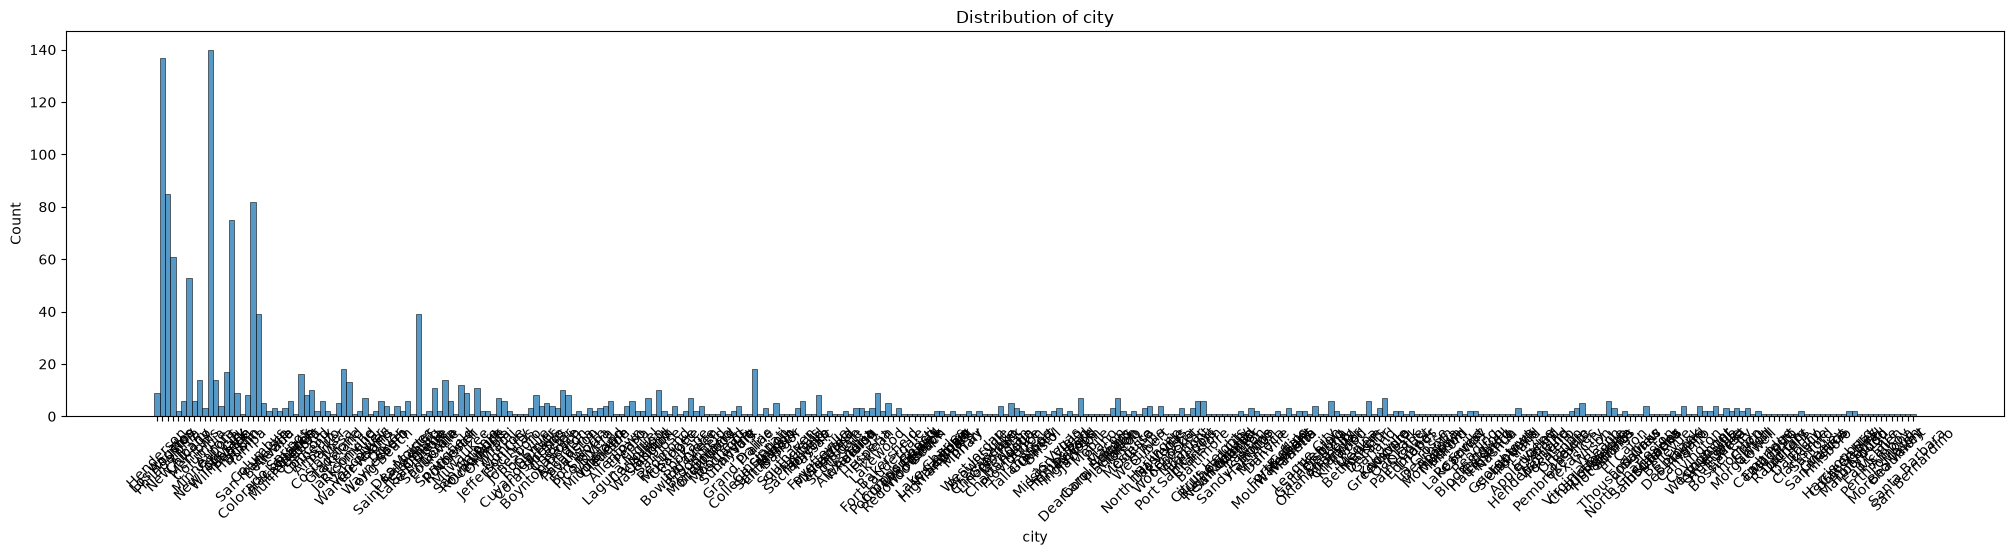

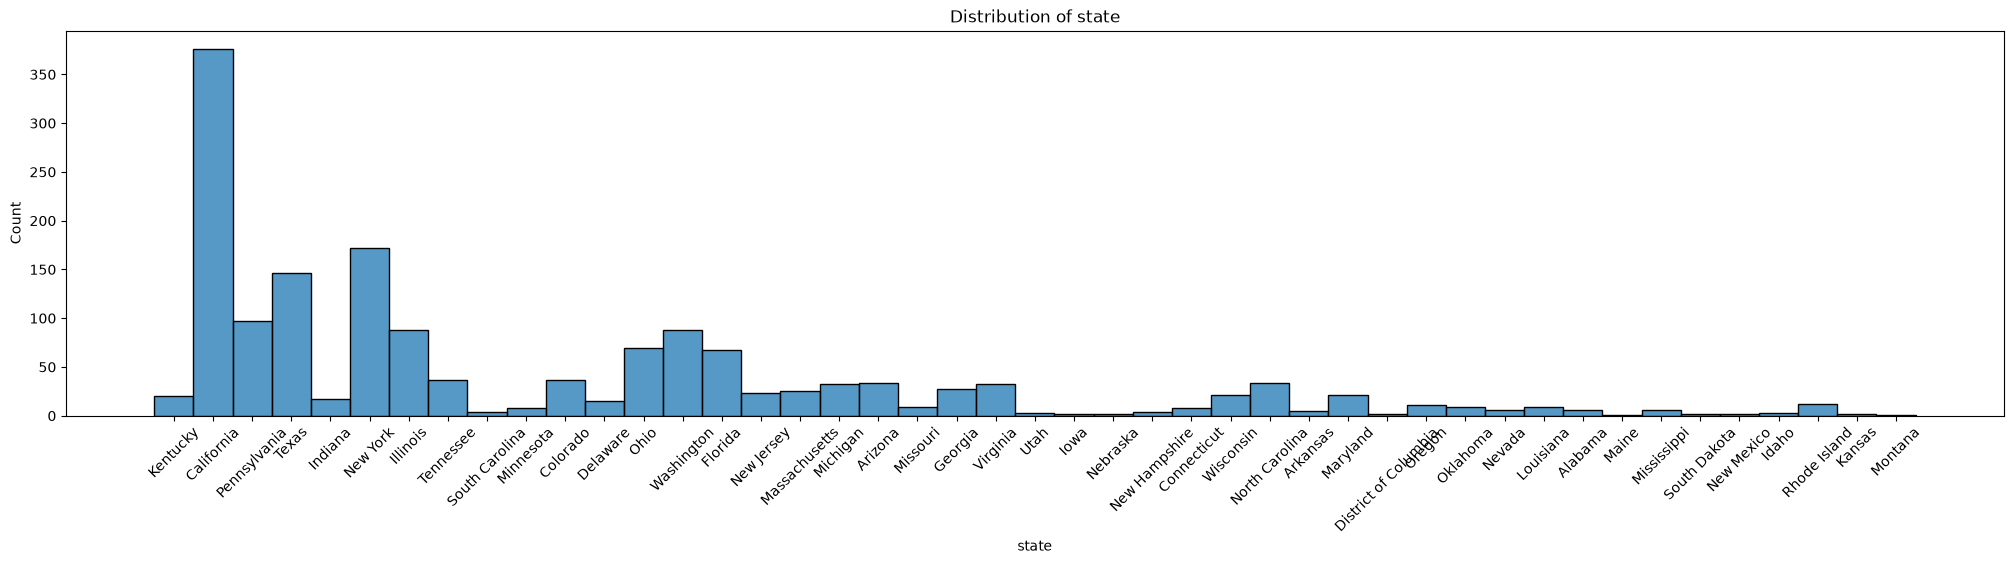

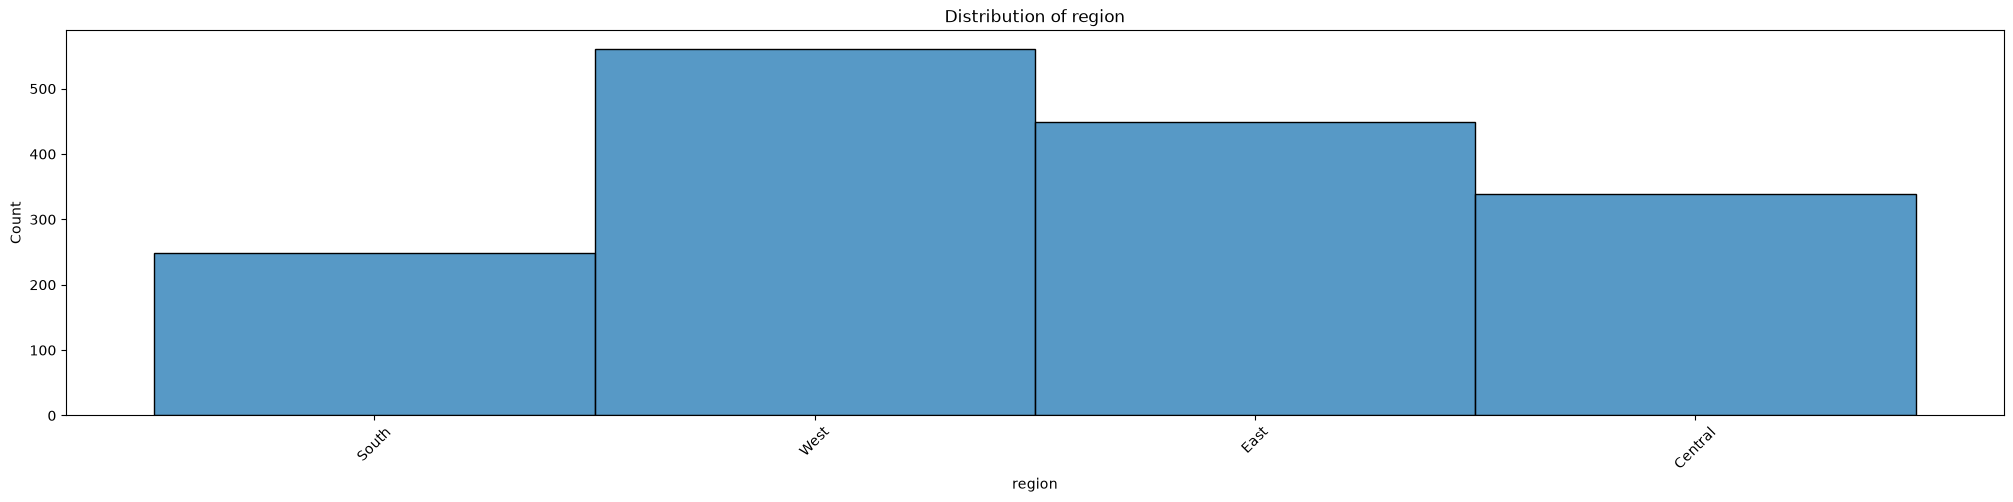

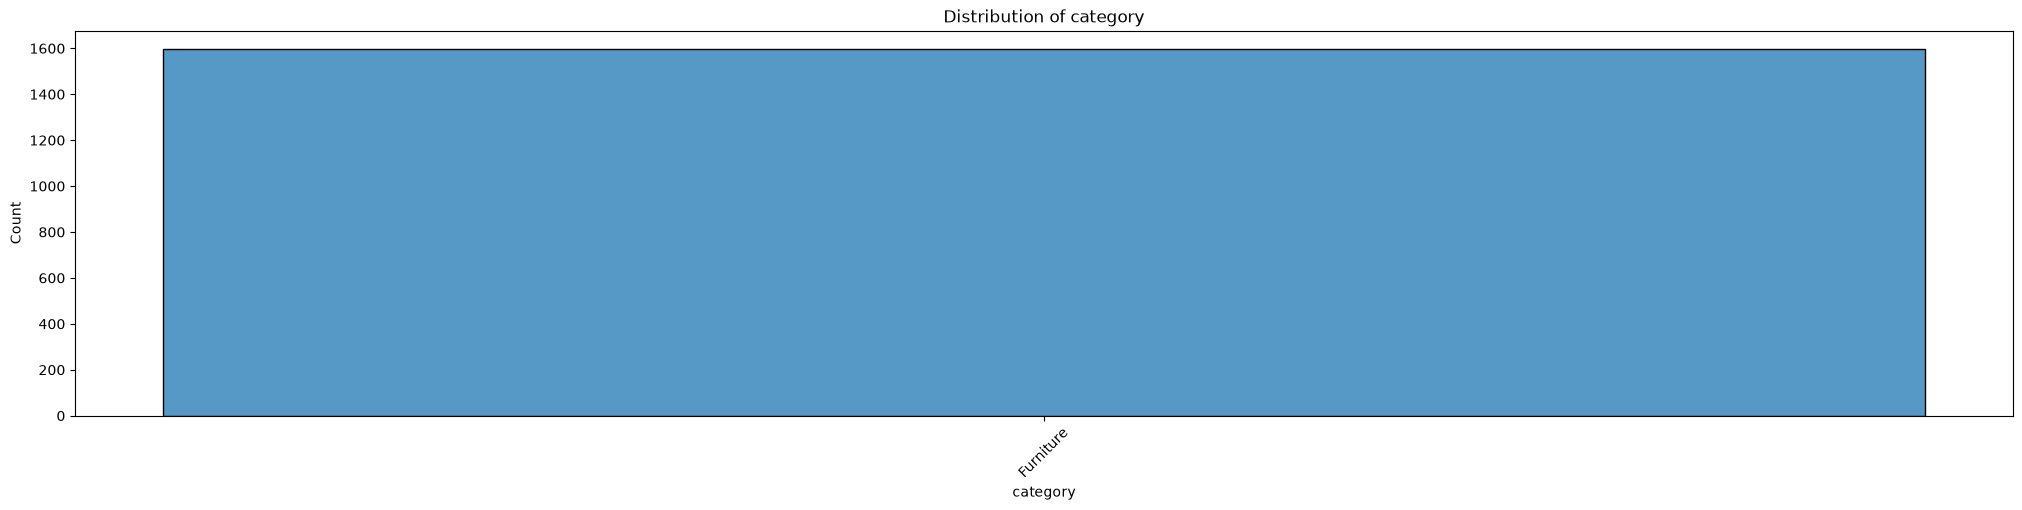

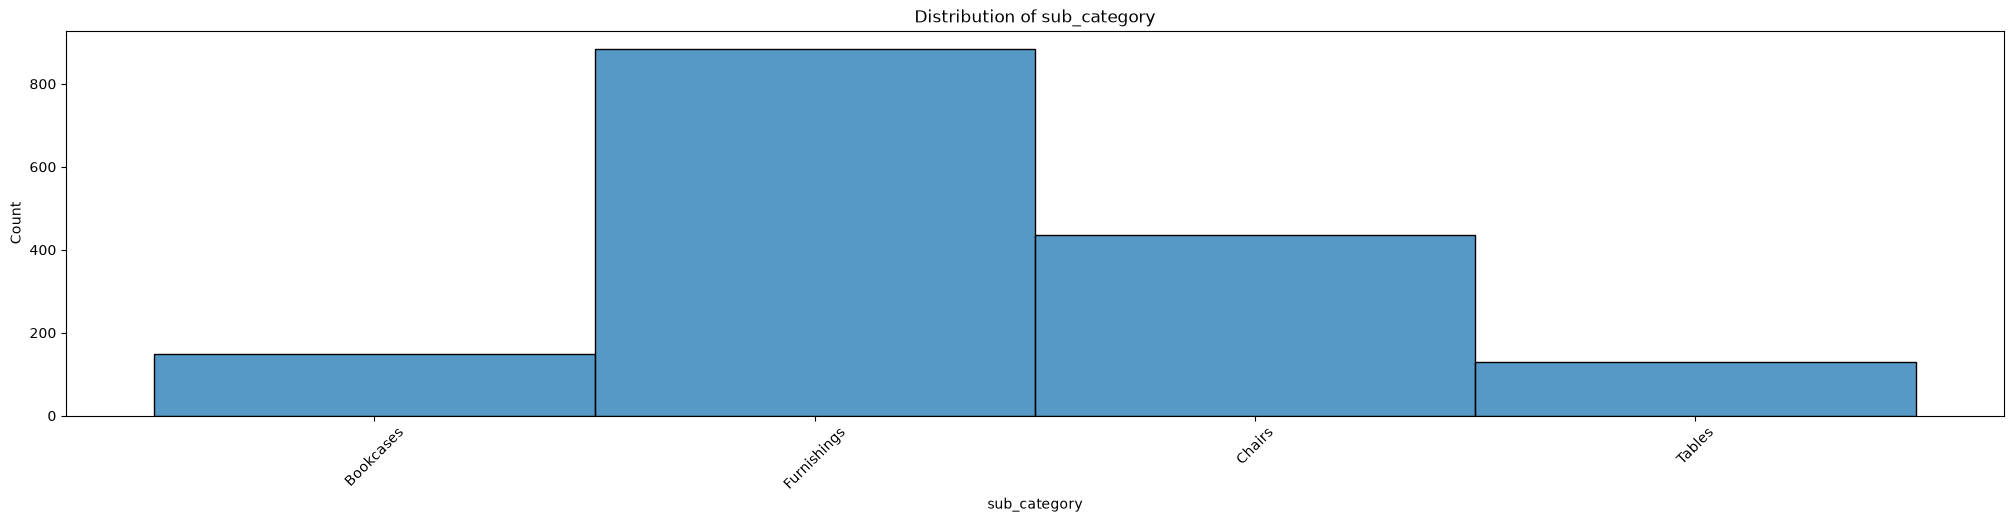

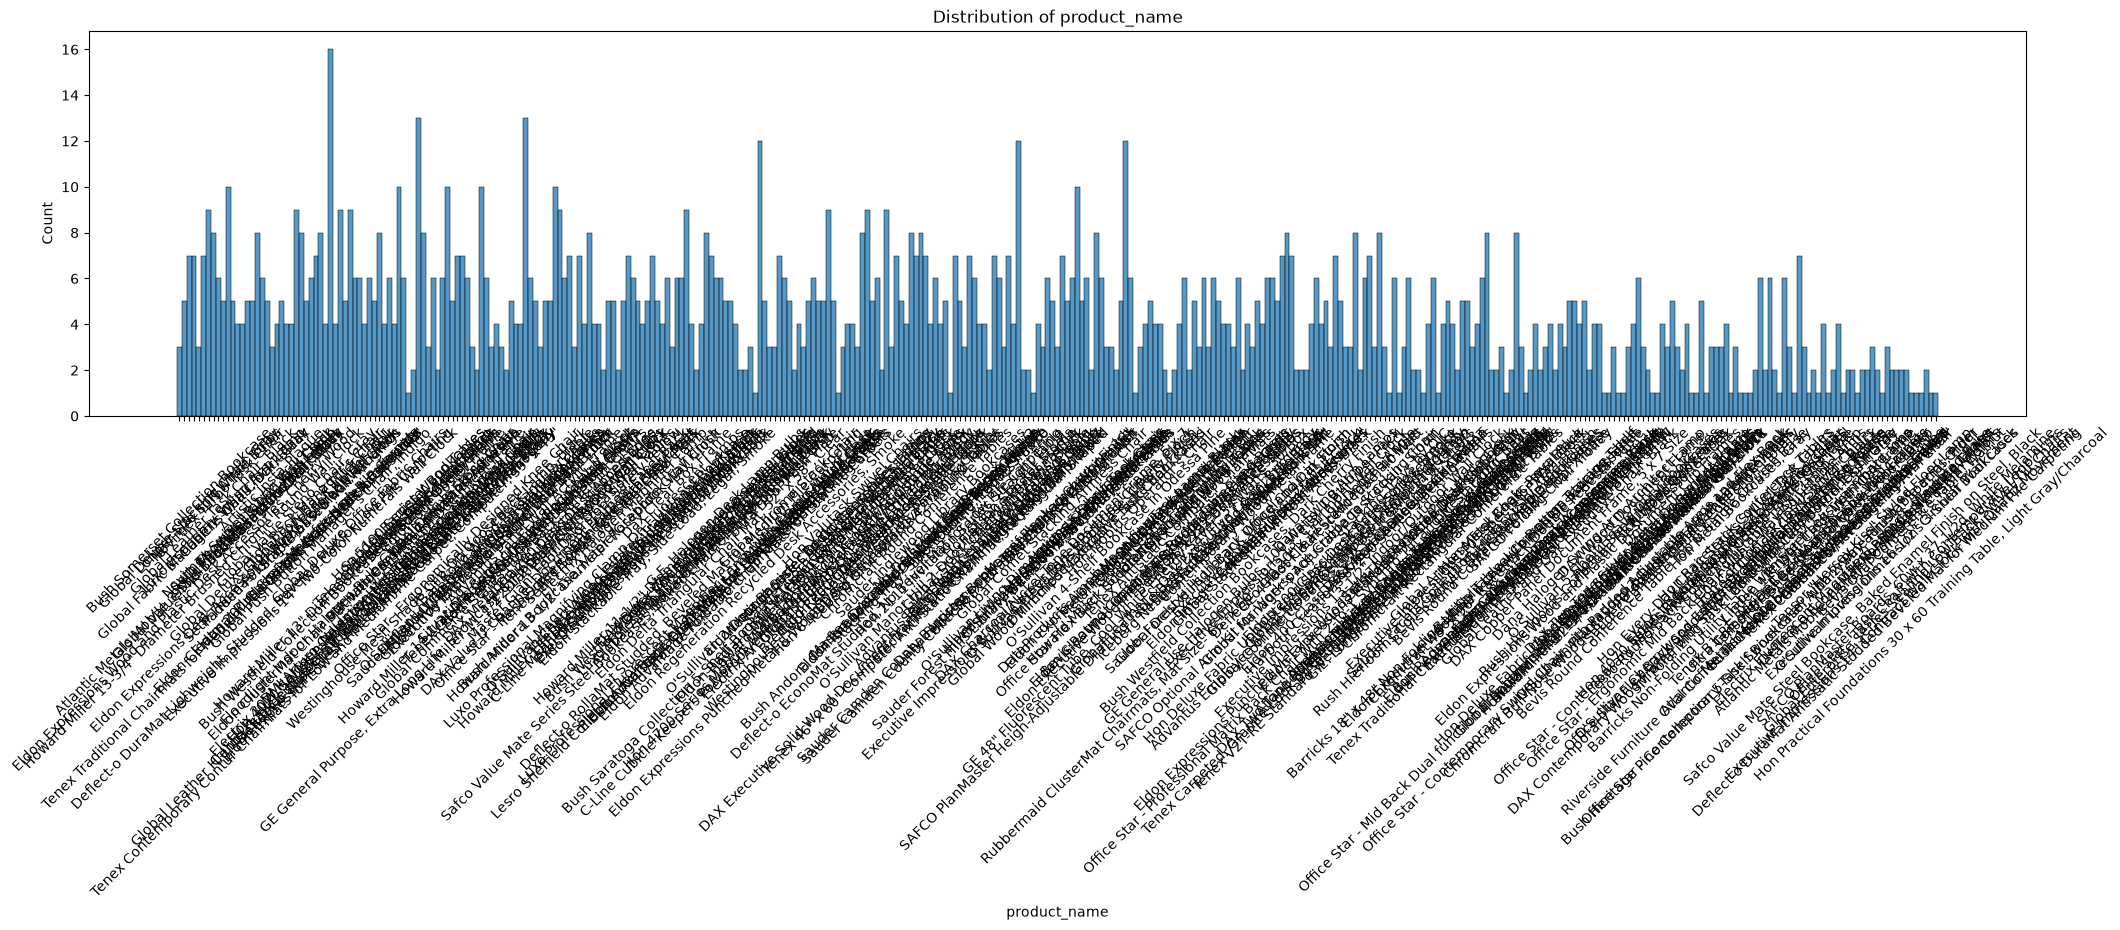

In [53]:
nums = df.select_dtypes(include=['str']).columns.tolist()
for n in nums:
    plt.figure(figsize=(25,5))
    sns.histplot(data=df, x=n)
    plt.title(f'Distribution of {n}')
    plt.xticks(rotation=45)
    plt.show()

Bivariate:

**Step 7: define feature and target**